In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')

In [2]:
#loading the dataset
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
#inspecting the dataset
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

print("Dataframe missing values:")
print(df.isnull().sum())

print("Dataframe duplicates:")
print(df.duplicated().sum())

#work on the duplicate
df = df.drop_duplicates()
print("Duplicates after removal:")
print(df.duplicated().sum())

# Check updated dataset dimensions
print("Updated dataset shape:", df.shape)

df.describe()

Dataset shape: (150, 5)

Column names:
Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB
Dataframe missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64
Dataframe duplicates:
1
Duplicates after removal:
0
Updated dataset shape: (149, 5)


,sepal_length,sepal_width,petal_length,petal_width
count,149.000000,149.000000,149.000000,149.000000
mean,5.843624,3.059732,3.748993,1.194631
std,0.830851,0.436342,1.767791,0.762622
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.300000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


species
setosa        50
versicolor    50
virginica     49
Name: count, dtype: int64


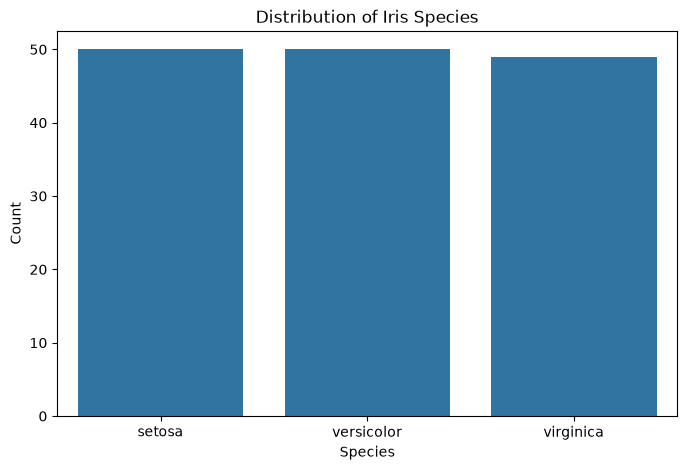

In [4]:
#checking target variable distribution
print(df['species'].value_counts())

# Visualize species distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='species')
plt.title('Distribution of Iris Species')
plt.xlabel('Species')
plt.ylabel('Count')
plt.show()

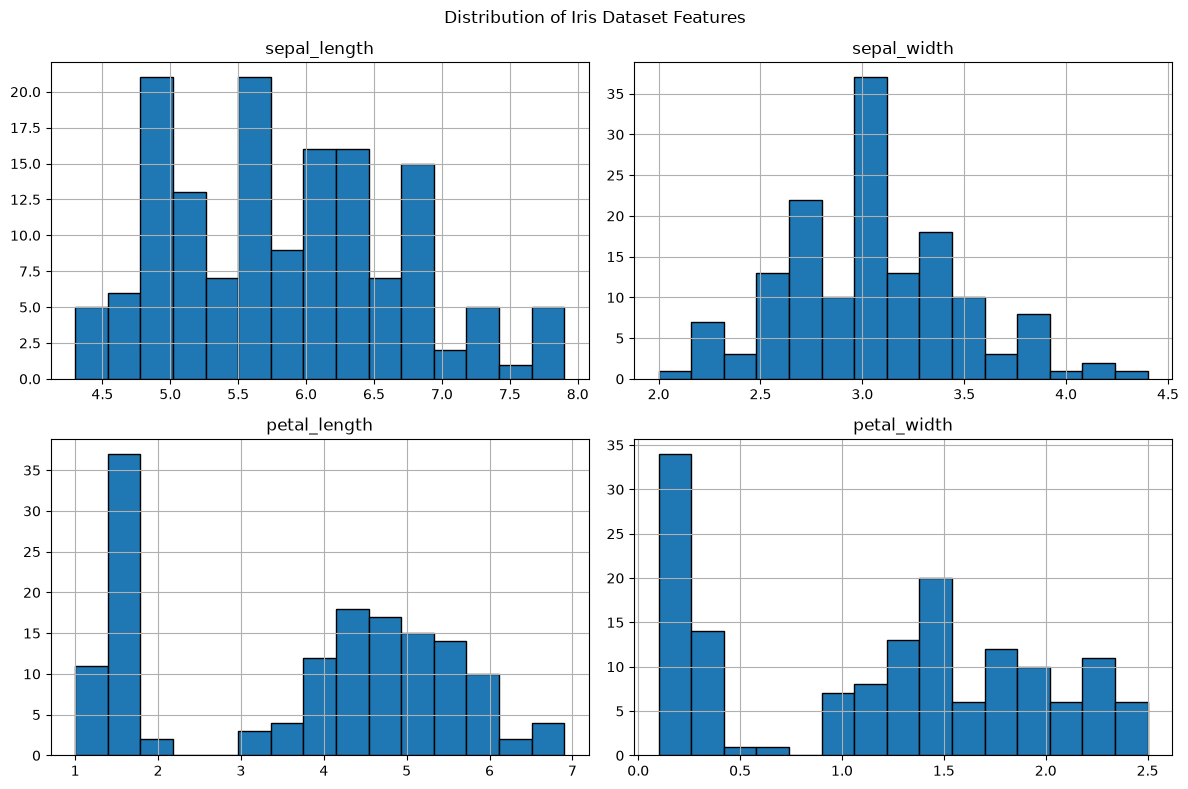

In [5]:
#distribution of numerical features
# Plot distributions of numerical features
df.hist(figsize=(12, 8), bins=15, edgecolor='black')
plt.suptitle('Distribution of Iris Dataset Features')
plt.tight_layout()
plt.show()

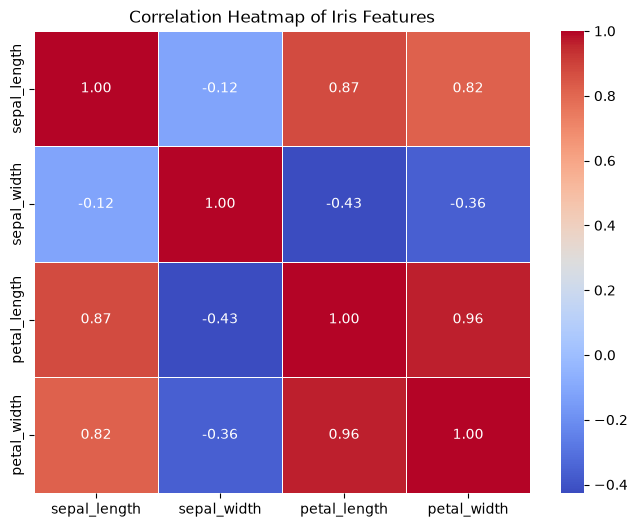

In [6]:
#relationships
# Calculate correlation matrix
correlation = df.select_dtypes(include=np.number).corr()

# Plot correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)
plt.title('Correlation Heatmap of Iris Features')
plt.show()

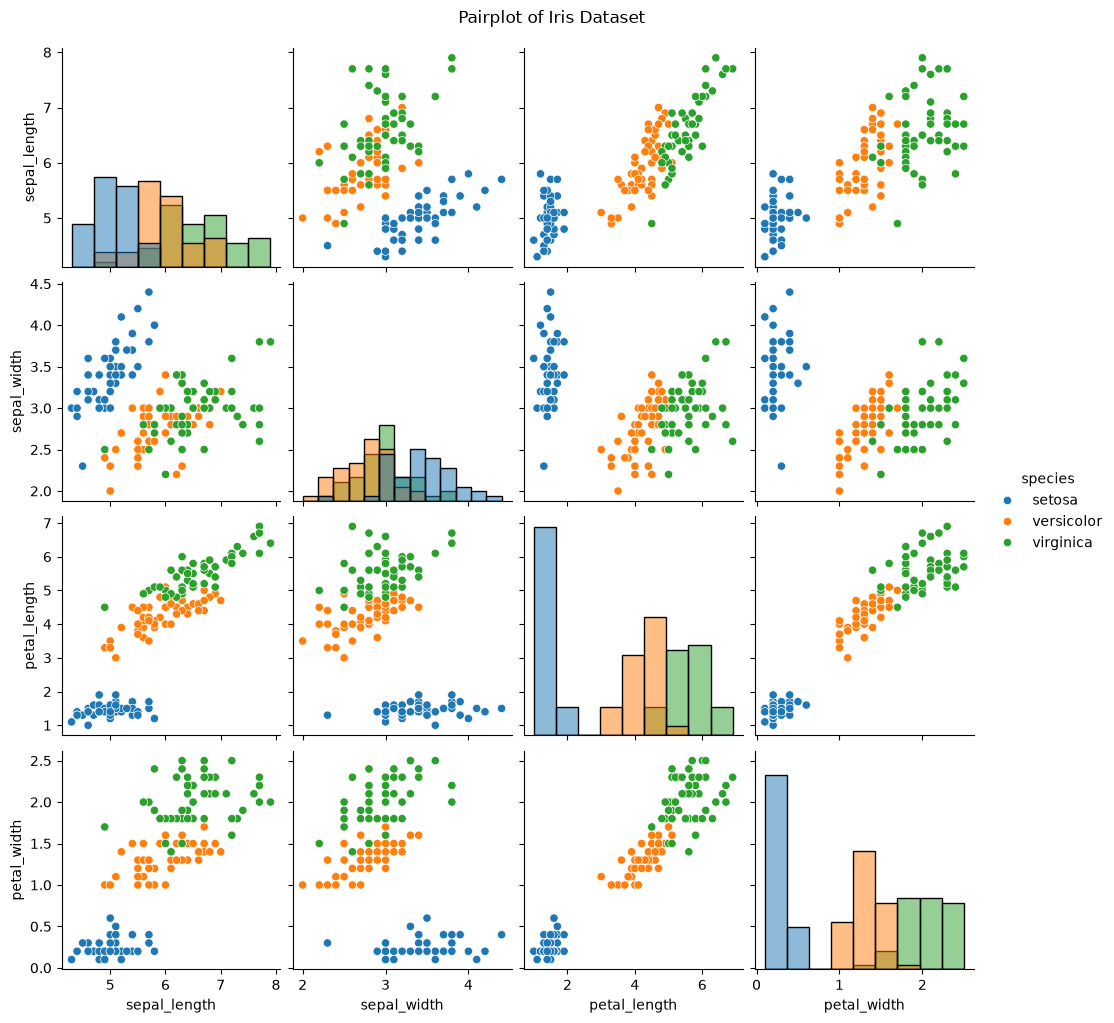

In [7]:
sns.pairplot(df, hue='species', diag_kind='hist')
plt.suptitle('Pairplot of Iris Dataset', y=1.02)
plt.show()

In [8]:
# Separate independent variables and target variable
X = df.drop('species', axis=1)
y = df['species']

# Display features and target
print("Features:")
display(X.head())

print("\nTarget:")
display(y.head())

Features:


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target:


0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: str

In [9]:
#encode the target variable
from sklearn.preprocessing import LabelEncoder

# Initialize label encoder
le = LabelEncoder()

# Encode target variable
y = le.fit_transform(y)

# Display encoded classes
print("Species encoding:")
for index, species in enumerate(le.classes_):
    print(f"{species}: {index}")

Species encoding:
setosa: 0
versicolor: 1
virginica: 2


In [10]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
# Display dataset sizes
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (119, 4)
Testing set: (30, 4)


In [11]:
#normalizing the features
# Initialize StandardScaler
scaler = StandardScaler()

# Fit scaler on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

# Display scaled training data
print("Scaled training data:")
display(pd.DataFrame(
    X_train_scaled,
    columns=X.columns
).head())

Scaled training data:


,sepal_length,sepal_width,petal_length,petal_width
0,-1.501587,0.769031,-1.339093,-1.179737
1,0.639824,-0.586742,1.041834,1.186365
2,-0.192947,-0.134818,0.248192,0.003314
3,-0.906751,1.672881,-1.055649,-1.048287
4,-1.263653,0.091144,-1.225715,-1.311187


In [12]:
#train logistic regression model
lr_model = LogisticRegression(random_state=42, max_iter=200)

# Train the model
lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [13]:
#train decision tree model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train_scaled, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [14]:
# Generate predictions using Logistic Regression
y_pred_lr = lr_model.predict(X_test_scaled)

# Generate predictions using Decision Tree
y_pred_dt = dt_model.predict(X_test_scaled)

print("Predictions generated successfully!")

Predictions generated successfully!


In [15]:
# Evaluate Logistic Regression
print("LOGISTIC REGRESSION PERFORMANCE")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print("Precision:", precision_score(y_test, y_pred_lr, average='weighted'))

print("Recall:", recall_score(y_test, y_pred_lr, average='weighted'))

print("F1-Score:", f1_score(y_test, y_pred_lr, average='weighted'))

LOGISTIC REGRESSION PERFORMANCE
Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1-Score: 0.9333333333333333


In [16]:
# Evaluate Decision Tree
print("DECISION TREE PERFORMANCE")

print("Accuracy:", accuracy_score(y_test, y_pred_dt))

print("Precision:", precision_score(y_test, y_pred_dt, average='weighted'))

print("Recall:", recall_score(y_test, y_pred_dt, average='weighted'))

print("F1-Score:", f1_score(y_test, y_pred_dt, average='weighted'))

DECISION TREE PERFORMANCE
Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1-Score: 0.9333333333333333


In [17]:
# Logistic Regression classification report
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_lr, target_names=le.classes_))

# Decision Tree classification report
print("DECISION TREE CLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_dt, target_names=le.classes_))

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

DECISION TREE CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [18]:
# Create model comparison table
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr, average='weighted'),
        precision_score(y_test, y_pred_dt, average='weighted')
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr, average='weighted'),
        recall_score(y_test, y_pred_dt, average='weighted')
    ],
    'F1-Score': [
        f1_score(y_test, y_pred_lr, average='weighted'),
        f1_score(y_test, y_pred_dt, average='weighted')
    ]
})

results

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
1,Decision Tree,0.933333,0.933333,0.933333,0.933333


Both Logistic Regression and Decision Tree achieved an accuracy of 93.33%, with identical weighted precision, recall and F1-scores. This indicates that the two models performed equally well on the testing dataset. Each model correctly classified 28 out of 30 observations, demonstrating strong classification performance. However, their equal overall metrics do not necessarily mean they made errors on the same observations. Further analysis using confusion matrices will help identify the specific classification errors made by each model.

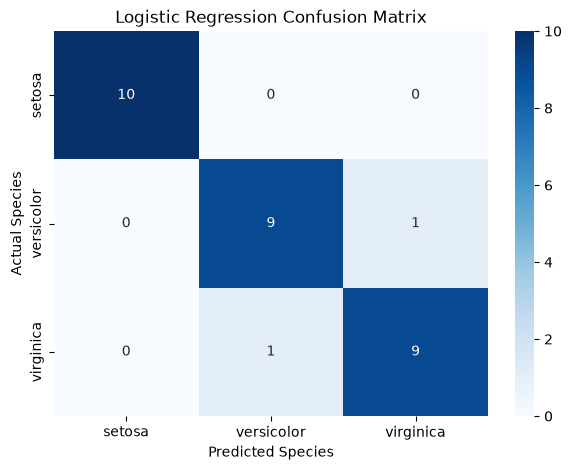

In [19]:
# Generate confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted Species')
plt.ylabel('Actual Species')
plt.show()

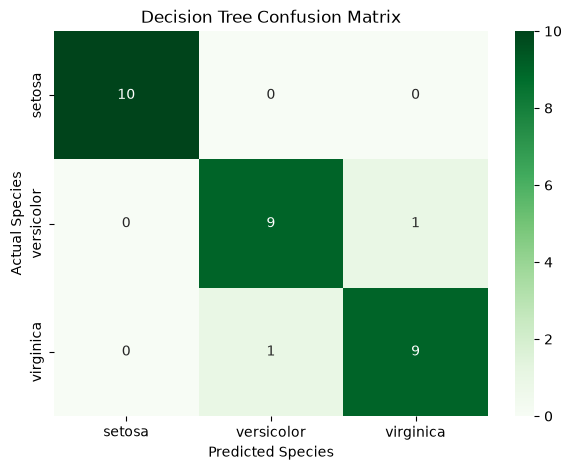

In [20]:
# Generate confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted Species')
plt.ylabel('Actual Species')
plt.show()

In [21]:
# Select two features for visualization
X_vis = df[['petal_length', 'petal_width']]
y_vis = le.transform(df['species'])

# Split the visualization dataset
X_train_vis, X_test_vis, y_train_vis, y_test_vis = train_test_split(
    X_vis,
    y_vis,
    test_size=0.2,
    random_state=42,
    stratify=y_vis
)

# Scale the features
scaler_vis = StandardScaler()

X_train_vis_scaled = scaler_vis.fit_transform(X_train_vis)
X_test_vis_scaled = scaler_vis.transform(X_test_vis)

In [22]:
# Train Logistic Regression
lr_vis = LogisticRegression(random_state=42, max_iter=200)
lr_vis.fit(X_train_vis_scaled, y_train_vis)

# Train Decision Tree
dt_vis = DecisionTreeClassifier(random_state=42)
dt_vis.fit(X_train_vis_scaled, y_train_vis)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [23]:
def plot_decision_boundary(model, X, y, title):

    # Define plot boundaries
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    # Generate coordinate points
    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, 0.02),
        np.arange(y_min, y_max, 0.02)
    )

    # Predict species for every coordinate point
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Plot decision regions
    plt.figure(figsize=(9, 6))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')

    # Plot actual observations
    scatter = plt.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        cmap='viridis',
        edgecolor='black'
    )

    plt.title(title)
    plt.xlabel('Petal Length (Standardized)')
    plt.ylabel('Petal Width (Standardized)')
    plt.legend(
        handles=scatter.legend_elements()[0],
        labels=le.classes_,
        title='Species'
    )

    plt.show()

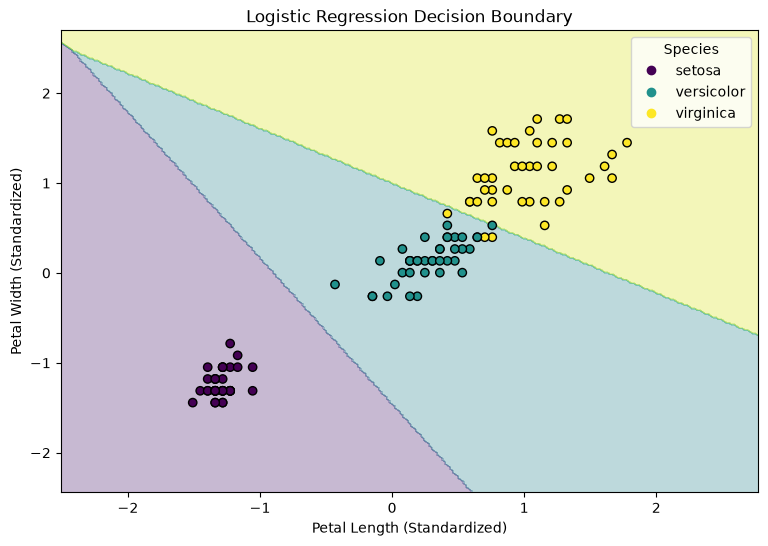

In [24]:
plot_decision_boundary(
    lr_vis,
    X_train_vis_scaled,
    y_train_vis,
    'Logistic Regression Decision Boundary'
)

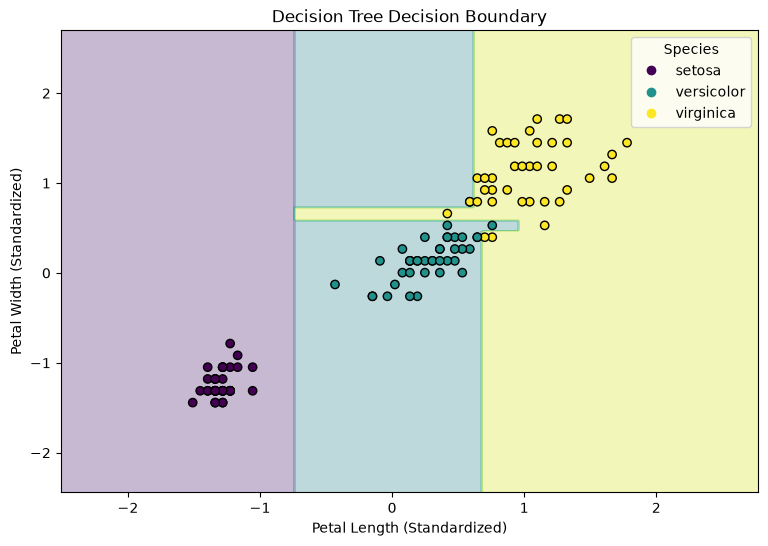

In [25]:
plot_decision_boundary(
    dt_vis,
    X_train_vis_scaled,
    y_train_vis,
    'Decision Tree Decision Boundary'
)